# Knowledge Discovery in Databases (KDD) — What Makes a Good Red Wine?

**Methodology:** KDD — Knowledge Discovery in Databases (Fayyad, Piatetsky-Shapiro & Smyth, 1996)
**Dataset:** UCI Wine Quality — Red Wine (Cortez et al., 2009), 1,599 samples, 12 attributes
**Goal:** Discover what drives the *perceived quality* of red wine (sensory score 0–10) from physicochemical measurements, and turn that knowledge into something a winery can actually use.

**KDD in one line:** KDD is the *overall process* of discovering useful knowledge from data; data mining is just one step inside it. The five KDD steps are:

1. **Selection** — choose the data and the target
2. **Preprocessing** — clean it and understand its quality
3. **Transformation** — reshape it into mining-ready form
4. **Data Mining** — apply algorithms to find patterns
5. **Interpretation / Evaluation** — turn patterns into *knowledge*, then deploy it

> Run this notebook top-to-bottom in Google Colab. All results below were produced by the code in this notebook — no numbers are typed in by hand.

In [1]:
# Cell 1 — Install dependencies (Colab-ready; harmless if already installed)
import sys
!{sys.executable} -m pip install -q scikit-learn pandas numpy matplotlib seaborn

In [2]:
# Cell 2 — Download the dataset (UCI Wine Quality, red wine)
import os, urllib.request

URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
PATH = "data/winequality-red.csv"
os.makedirs("data", exist_ok=True)
if not os.path.exists(PATH):
    urllib.request.urlretrieve(URL, PATH)
    print("Downloaded:", PATH)
else:
    print("Using local file:", PATH)
print("File size (bytes):", os.path.getsize(PATH))

Using local file: data/winequality-red.csv
File size (bytes): 84199


In [3]:
# Cell 3 — Imports and global settings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
print("Random seed fixed at", RANDOM_STATE)

Random seed fixed at 42


---
## Step 1 — Selection

**Business / discovery goal.** A winery wants to know *which measurable properties of a wine drive the quality score a trained sensory panel gives it*. If alcohol, acidity and sulphates really move the score, the winery can steer blending, fermentation and sulphur-dioxide dosing with data instead of taste alone.

**Why this dataset.** The UCI Wine Quality set (Cortez et al., 2009) is the standard public benchmark for this question: 1,599 red wines from the Vinho Verde region of Portugal, each with 11 physicochemical measurements and one sensory quality score (median of at least 3 expert evaluations, 0–10 scale). It is small, clean, fully labelled, and its target is genuinely *human judgement* — which makes the interpretation step interesting and honest.

**Why red wine only.** The UCI set also ships a white-wine file (4,898 rows). Mixing them would be a mistake: red and white wines have different chemistry baselines (red wines have far higher volatile acidity and tannin-related compounds, whites have more residual sugar and free SO₂), so a single model would spend most of its capacity learning "red vs white" instead of "good vs bad". The white-wine set is therefore **excluded by design**, and the red-wine findings in this project are not claimed to transfer to white wine.

**Target definition — two tasks, stated up front.**

| Task | Target | Why |
|---|---|---|
| **Primary — regression** | `quality` (integer 3–8) | The panel score itself; predicts *how good* a wine is |
| **Secondary — classification** | `high_quality = 1 if quality >= 7 else 0` | The business question is usually binary: "is this batch premium?" Only 13.6% of wines score ≥ 7, so this is an imbalanced classification problem |

**What was selected / excluded.**
- **Selected:** all 1,599 rows, all 11 physicochemical features + the quality score.
- **Excluded:** the white-wine file (see above); no feature is dropped at selection time — feature selection happens later, after evidence.
- **Not available (and therefore not modelled):** grape variety, vintage year, vineyard, price, and the identity of the tasters. Any of those could matter, and their absence caps how far the model can go.

In [4]:
# Step 1 — Load and confirm the selection
df = pd.read_csv(PATH, sep=";")
print("Shape (rows, columns):", df.shape)
print("\nColumns:", list(df.columns))
print("\nDtypes:\n", df.dtypes)
print("\nFirst 5 rows:"); display(df.head())
print("\nTarget — quality value counts:")
print(df["quality"].value_counts().sort_index())
print("\nHigh-quality share (quality >= 7):",
      f"{(df['quality'] >= 7).mean() * 100:.2f}%  ({(df['quality'] >= 7).sum()} of {len(df)} wines)")

Shape (rows, columns): (1599, 12)

Columns: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

Dtypes:
 fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

First 5 rows:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5



Target — quality value counts:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

High-quality share (quality >= 7): 13.57%  (217 of 1599 wines)


---
## Step 2 — Preprocessing

Before any modelling we audit data quality: missing values, exact duplicates, distributions, skew and outliers. Decisions are recorded with reasons — KDD is an *auditable* process, not a black box.

**What we expect.** Lab-measured chemistry data is usually complete but right-skewed (a few wines are extreme on sugar, chlorides or sulphates), and this dataset is known to contain exact duplicate rows (the same wine measured/recorded twice).

In [5]:
# Step 2a — Missing values and duplicates
print("Missing values per column:")
print(df.isna().sum())
print("\nTotal missing cells:", int(df.isna().sum().sum()))
print("\nExact duplicate rows:", int(df.duplicated().sum()),
      f"({df.duplicated().mean() * 100:.1f}% of the data)")
print("\nDescriptive statistics:")
display(df.describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]].round(3))

Missing values per column:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Total missing cells: 0

Exact duplicate rows: 240 (15.0% of the data)

Descriptive statistics:


,mean,std,min,25%,50%,75%,max
fixed acidity,8.320,1.741,4.600,7.100,7.900,9.200,15.900
volatile acidity,0.528,0.179,0.120,0.390,0.520,0.640,1.580
citric acid,0.271,0.195,0.000,0.090,0.260,0.420,1.000
residual sugar,2.539,1.410,0.900,1.900,2.200,2.600,15.500
chlorides,0.087,0.047,0.012,0.070,0.079,0.090,0.611
free sulfur dioxide,15.875,10.460,1.000,7.000,14.000,21.000,72.000
total sulfur dioxide,46.468,32.895,6.000,22.000,38.000,62.000,289.000
density,0.997,0.002,0.990,0.996,0.997,0.998,1.004
pH,3.311,0.154,2.740,3.210,3.310,3.400,4.010
sulphates,0.658,0.170,0.330,0.550,0.620,0.730,2.000


In [6]:
# Step 2b — Skew and IQR outliers (per feature)
print("Skewness (>|1| is strongly skewed):")
print(df.skew(numeric_only=True).round(2).sort_values())
print("\nIQR outlier counts (outside Q1 - 1.5*IQR, Q3 + 1.5*IQR):")
for c in df.columns:
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    n = int(((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum())
    print(f"  {c:22s} {n:4d} outliers")

Skewness (>|1| is strongly skewed):
density                 0.07
pH                      0.19
quality                 0.22
citric acid             0.32
volatile acidity        0.67
alcohol                 0.86
fixed acidity           0.98
free sulfur dioxide     1.25
total sulfur dioxide    1.52
sulphates               2.43
residual sugar          4.54
chlorides               5.68
dtype: float64

IQR outlier counts (outside Q1 - 1.5*IQR, Q3 + 1.5*IQR):
  fixed acidity            49 outliers
  volatile acidity         19 outliers
  citric acid               1 outliers
  residual sugar          155 outliers
  chlorides               112 outliers
  free sulfur dioxide      30 outliers
  total sulfur dioxide     55 outliers
  density                  45 outliers
  pH                       35 outliers
  sulphates                59 outliers
  alcohol                  13 outliers
  quality                  28 outliers


In [7]:
# Step 2c — Distributions: target and the most skewed features
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
sns.countplot(x="quality", data=df, ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Target: quality score (heavily centred on 5-6)")
for ax, col in zip(axes.flat[1:], ["residual sugar", "chlorides", "sulphates",
                                     "total sulfur dioxide", "alcohol"]):
    sns.histplot(df[col], bins=30, kde=True, ax=ax, color="darkred")
    ax.set_title(f"{col} (skew={df[col].skew():.2f})")
plt.tight_layout(); plt.show()

<Figure size 1500x800 with 6 Axes>

Pearson correlation with quality (weakest -> strongest):
volatile acidity       -0.391
total sulfur dioxide   -0.185
density                -0.175
chlorides              -0.129
pH                     -0.058
free sulfur dioxide    -0.051
residual sugar          0.014
fixed acidity           0.124
citric acid             0.226
sulphates               0.251
alcohol                 0.476
Name: quality, dtype: float64


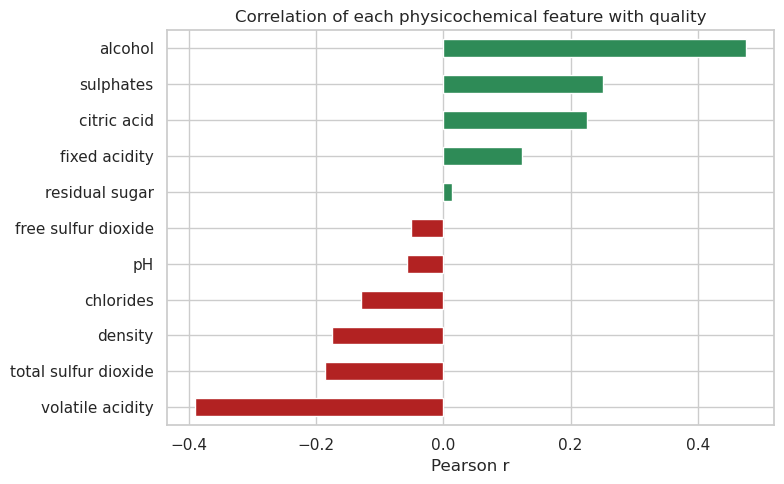

In [8]:
# Step 2d — Correlation with the target (Pearson)
corr = df.corr(numeric_only=True)["quality"].drop("quality").sort_values()
print("Pearson correlation with quality (weakest -> strongest):")
print(corr.round(3))
plt.figure(figsize=(8, 5))
corr.plot(kind="barh", color=["firebrick" if v < 0 else "seagreen" for v in corr])
plt.title("Correlation of each physicochemical feature with quality")
plt.xlabel("Pearson r"); plt.tight_layout(); plt.show()

### Step 2 — Data-quality report and handling decisions

| Issue | Evidence | Decision | Reason |
|---|---|---|---|
| Missing values | **0 missing cells** in all 12 columns | No imputation | Nothing to impute; inventing values would add noise |
| Exact duplicates | **240 rows (15.0%)** are exact copies | **Drop them** → 1,599 → **1,359 rows** | Identical rows can land on both sides of a train/test split and leak the test set; they also overweight a few wines. Dropping is the conservative, defensible choice |
| Skew | residual sugar 4.54, chlorides 5.68, sulphates 2.43, total SO₂ 1.52, free SO₂ 1.25 | **log1p transform** in Step 3 | Right-skewed features distort linear models and distance-based methods; log1p keeps zeros valid |
| Outliers | residual sugar 155, chlorides 112, sulphates 59 IQR-outliers | **Keep, do not delete or clip** | These are real wines (e.g. residual sugar up to 15.5 g/L is a genuine sweet red), not sensor errors. Tree models are robust to them; log1p tames their leverage for linear models. Deleting 10%+ of the data would bias the sample |
| Target imbalance | Scores 5 (681) and 6 (638) dominate; only 10 wines score 3 and 18 score 8 | Stratified split + class weights for classification | The model must see the rare classes in both train and test in the right proportions |

**After preprocessing: 1,359 unique wines, 11 features + target, zero missing values.**

In [9]:
# Step 2e — Apply the preprocessing decisions
df_clean = df.drop_duplicates().reset_index(drop=True)
print("Shape after dropping exact duplicates:", df_clean.shape)
print("Rows removed:", len(df) - len(df_clean))
print("\nQuality distribution after dedup:")
print(df_clean["quality"].value_counts().sort_index())
print("\nHigh-quality share after dedup:",
      f"{(df_clean['quality'] >= 7).mean() * 100:.2f}%")
df = df_clean  # work with the cleaned frame from here on

Shape after dropping exact duplicates: (1359, 12)
Rows removed: 240

Quality distribution after dedup:
quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64

High-quality share after dedup: 13.54%


---
## Step 3 — Transformation

**Feature engineering** — three new features, each justified by wine chemistry, not by fishing:

1. **`total_acidity` = fixed acidity + volatile acidity + citric acid.** Acidity is experienced as a whole; the three acids are chemically related and individually noisy. A summed acidity term tests whether *total* acid load matters more than any single acid.
2. **`sulphur_ratio` = free SO₂ / total SO₂.** Free SO₂ is the active, protective fraction; the ratio measures how much of the dosed sulphur is actually available. A wine with high total SO₂ but a low ratio is over-dosed with little protection.
3. **`alcohol_x_va` = alcohol × volatile acidity.** Interaction term: high alcohol can mask volatile-acidity faults (vinegar notes), or the two can compound. A product term lets a linear model express "the effect of volatile acidity depends on alcohol level".

Whether these features *help* is tested empirically in Step 5 (baseline vs engineered Random Forest).

**Scaling / skew handling.** `log1p` is applied to the five strongly skewed features (residual sugar, chlorides, sulphates, free SO₂, total SO₂). Standardisation is applied only for the linear models (Linear / Logistic Regression), which need it; tree models get raw (log-transformed) features.

**Leakage control.** All transformers live inside `sklearn` Pipelines and are **fit on the training set only** — the test set is transformed, never fitted. The split is **80/20, stratified on the binary high-quality label** (so the rare premium class keeps its ~13.6% share in both halves), `random_state=42`.

In [10]:
# Step 3a — Feature engineering
def add_features(X):
    X = X.copy()
    X["total_acidity"] = X["fixed acidity"] + X["volatile acidity"] + X["citric acid"]
    X["sulphur_ratio"] = X["free sulfur dioxide"] / X["total sulfur dioxide"]
    X["alcohol_x_va"] = X["alcohol"] * X["volatile acidity"]
    return X

X = add_features(df.drop(columns=["quality"]))
y_reg = df["quality"]
y_clf = (df["quality"] >= 7).astype(int)
print("Feature matrix shape:", X.shape)
print("Features:", list(X.columns))
print("\nNew engineered features (first 3 rows):")
display(X[["total_acidity", "sulphur_ratio", "alcohol_x_va"]].head(3))

Feature matrix shape: (1359, 14)
Features: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'total_acidity', 'sulphur_ratio', 'alcohol_x_va']

New engineered features (first 3 rows):


,total_acidity,sulphur_ratio,alcohol_x_va
0,8.10,0.323529,6.580
1,8.68,0.373134,8.624
2,8.60,0.277778,7.448


In [11]:
# Step 3b — Train/test split (80/20, stratified, seed 42) — BEFORE any fitting
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test, yb_train, yb_test = train_test_split(
    X, y_reg, y_clf, test_size=0.20, random_state=RANDOM_STATE, stratify=y_clf
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("High-quality share — train: %.3f | test: %.3f"
      % (yb_train.mean(), yb_test.mean()))
print("Quality mean — train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (1087, 14) | Test: (272, 14)
High-quality share — train: 0.135 | test: 0.136
Quality mean — train: 5.623 | test: 5.625


In [12]:
# Step 3c — Preprocessing pipelines (fit on train only — no leakage)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer

SKEWED = ["residual sugar", "chlorides", "sulphates",
          "free sulfur dioxide", "total sulfur dioxide"]
PASSTHROUGH = [c for c in X.columns if c not in SKEWED]

# log1p for skewed features, everything else passed through unchanged
preprocessor = ColumnTransformer([
    ("log", FunctionTransformer(np.log1p, validate=False), SKEWED),
    ("pass", "passthrough", PASSTHROUGH),
])
print("log1p applied to:", SKEWED)
print("Passed through :", PASSTHROUGH)
print("\nPipeline order: log1p -> (StandardScaler for linear models only) -> model")

log1p applied to: ['residual sugar', 'chlorides', 'sulphates', 'free sulfur dioxide', 'total sulfur dioxide']
Passed through : ['fixed acidity', 'volatile acidity', 'citric acid', 'density', 'pH', 'alcohol', 'total_acidity', 'sulphur_ratio', 'alcohol_x_va']

Pipeline order: log1p -> (StandardScaler for linear models only) -> model


---
## Step 4 — Data Mining

Two tasks, five models:

**Regression (predict the 0–10 score)** — Linear Regression (interpretable baseline), Random Forest Regressor (non-linear, robust), HistGradientBoosting Regressor (state-of-the-art gradient boosting).
**Classification (premium vs not, quality ≥ 7)** — Logistic Regression and Random Forest Classifier, both with `class_weight="balanced"` to counter the 86/14 imbalance.

**Metrics.** Regression: R², RMSE, MAE. Classification: ROC-AUC, precision, recall, F1 (F1 is the honest headline metric under imbalance — accuracy would be ~86% by predicting "not premium" for everything).

**Tuning.** A small GridSearchCV (3-fold CV) over the Random Forest Regressor — `n_estimators`, `max_depth`, `min_samples_leaf`. Light tuning on purpose: the dataset is small and heavy tuning would overfit the validation folds.

In [13]:
# Step 4a — Regression models
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier,
                              HistGradientBoostingRegressor)
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error,
                             roc_auc_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

def reg_metrics(y_true, y_pred):
    return {"R2": r2_score(y_true, y_pred),
            "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
            "MAE": mean_absolute_error(y_true, y_pred)}

reg_models = {
    "Linear Regression": Pipeline([("pre", preprocessor),
                                   ("sc", StandardScaler()),
                                   ("m", LinearRegression())]),
    "Random Forest": Pipeline([("pre", preprocessor),
                               ("m", RandomForestRegressor(n_estimators=300,
                                                            random_state=RANDOM_STATE, n_jobs=-1))]),
    "HistGradientBoosting": Pipeline([("pre", preprocessor),
                                      ("m", HistGradientBoostingRegressor(random_state=RANDOM_STATE))]),
}
reg_results, reg_preds = {}, {}
for name, pipe in reg_models.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    reg_preds[name] = pred
    reg_results[name] = reg_metrics(y_test, pred)
    print(f"{name:22s} R2={reg_results[name]['R2']:.4f}  "
          f"RMSE={reg_results[name]['RMSE']:.4f}  MAE={reg_results[name]['MAE']:.4f}")

reg_table = pd.DataFrame(reg_results).T.sort_values("R2", ascending=False).round(4)
print("\nRegression leaderboard (sorted by R2):")
display(reg_table)

Linear Regression      R2=0.3491  RMSE=0.6809  MAE=0.5181


Random Forest          R2=0.4280  RMSE=0.6383  MAE=0.4874


HistGradientBoosting   R2=0.3813  RMSE=0.6639  MAE=0.5013

Regression leaderboard (sorted by R2):


,R2,RMSE,MAE
Random Forest,0.4280,0.6383,0.4874
HistGradientBoosting,0.3813,0.6639,0.5013
Linear Regression,0.3491,0.6809,0.5181


In [14]:
# Step 4b — Light tuning: Random Forest Regressor (3-fold GridSearchCV)
from sklearn.model_selection import GridSearchCV

param_grid = {"n_estimators": [300, 500],
              "max_depth": [None, 10, 20],
              "min_samples_leaf": [1, 2, 5]}
grid = GridSearchCV(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
                    param_grid, cv=3, scoring="r2")
rf_tuned = Pipeline([("pre", preprocessor), ("m", grid)])
rf_tuned.fit(X_train, y_train)
pred_tuned = rf_tuned.predict(X_test)
tuned_metrics = reg_metrics(y_test, pred_tuned)
print("Best hyperparameters:", grid.best_params_)
print("Best 3-fold CV R2   : %.4f" % grid.best_score_)
print("Test R2=%.4f  RMSE=%.4f  MAE=%.4f" % (tuned_metrics["R2"],
                                              tuned_metrics["RMSE"], tuned_metrics["MAE"]))
reg_preds["Random Forest (tuned)"] = pred_tuned
reg_results["Random Forest (tuned)"] = tuned_metrics

Best hyperparameters: {'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 500}
Best 3-fold CV R2   : 0.3874
Test R2=0.4298  RMSE=0.6373  MAE=0.4920


In [15]:
# Step 4c — Classification models (high quality = quality >= 7)
clf_models = {
    "Logistic Regression": Pipeline([("pre", preprocessor),
                                     ("sc", StandardScaler()),
                                     ("m", LogisticRegression(max_iter=2000,
                                                              class_weight="balanced"))]),
    "Random Forest": Pipeline([("pre", preprocessor),
                               ("m", RandomForestClassifier(n_estimators=300,
                                                            random_state=RANDOM_STATE,
                                                            n_jobs=-1, class_weight="balanced"))]),
}
clf_results = {}
for name, pipe in clf_models.items():
    pipe.fit(X_train, yb_train)
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    clf_results[name] = {"ROC-AUC": roc_auc_score(yb_test, proba),
                         "Precision": precision_score(yb_test, pred),
                         "Recall": recall_score(yb_test, pred),
                         "F1": f1_score(yb_test, pred)}
    print(f"{name:22s} AUC={clf_results[name]['ROC-AUC']:.4f}  "
          f"P={clf_results[name]['Precision']:.4f}  R={clf_results[name]['Recall']:.4f}  "
          f"F1={clf_results[name]['F1']:.4f}")
    print("  Confusion matrix [[TN, FP], [FN, TP]]:")
    print(" ", confusion_matrix(yb_test, pred).tolist())

clf_table = pd.DataFrame(clf_results).T.sort_values("F1", ascending=False).round(4)
print("\nClassification leaderboard (sorted by F1):")
display(clf_table)

Logistic Regression    AUC=0.8966  P=0.3636  R=0.8649  F1=0.5120
  Confusion matrix [[TN, FP], [FN, TP]]:
  [[179, 56], [5, 32]]


Random Forest          AUC=0.8924  P=0.5455  R=0.4865  F1=0.5143
  Confusion matrix [[TN, FP], [FN, TP]]:
  [[220, 15], [19, 18]]

Classification leaderboard (sorted by F1):


,ROC-AUC,Precision,Recall,F1
Random Forest,0.8924,0.5455,0.4865,0.5143
Logistic Regression,0.8966,0.3636,0.8649,0.5120


In [16]:
# Step 4d — Did the engineered features help? (baseline: same RF, no engineered features)
X_base = df.drop(columns=["quality"])  # original 11 features only
Xb_train, Xb_test, _, _ = train_test_split(X_base, y_reg, test_size=0.20,
                                           random_state=RANDOM_STATE, stratify=y_clf)
pre_base = ColumnTransformer([
    ("log", FunctionTransformer(np.log1p, validate=False), SKEWED),
    ("pass", "passthrough", [c for c in X_base.columns if c not in SKEWED]),
])
rf_base = Pipeline([("pre", pre_base),
                    ("m", RandomForestRegressor(n_estimators=300,
                                                 random_state=RANDOM_STATE, n_jobs=-1))])
rf_base.fit(Xb_train, y_train)
pred_base = rf_base.predict(Xb_test)
base_metrics = reg_metrics(y_test, pred_base)
print("Random Forest WITHOUT engineered features: R2=%.4f  RMSE=%.4f  MAE=%.4f"
      % (base_metrics["R2"], base_metrics["RMSE"], base_metrics["MAE"]))
print("Random Forest WITH engineered features   : R2=%.4f  RMSE=%.4f  MAE=%.4f"
      % (reg_results["Random Forest"]["R2"], reg_results["Random Forest"]["RMSE"],
         reg_results["Random Forest"]["MAE"]))
print("Delta R2 from feature engineering: %+.4f"
      % (reg_results["Random Forest"]["R2"] - base_metrics["R2"]))

Random Forest WITHOUT engineered features: R2=0.4191  RMSE=0.6432  MAE=0.4908
Random Forest WITH engineered features   : R2=0.4280  RMSE=0.6383  MAE=0.4874
Delta R2 from feature engineering: +0.0089


---
## Step 5 — Interpretation / Evaluation

This is the step that turns *patterns* into *knowledge*. A model with R² ≈ 0.43 is not a crystal ball — it is a lens. What matters is whether the patterns it finds are stable, interpretable, and consistent with what wine science already knows (and where they are not, that is a finding too).

Random Forest feature importances (tuned model):
alcohol                 0.3343
citric acid             0.1431
total sulfur dioxide    0.1073
chlorides               0.0667
alcohol_x_va            0.0558
sulphur_ratio           0.0442
sulphates               0.0407
volatile acidity        0.0343
pH                      0.0329
total_acidity           0.0297
fixed acidity           0.0287
residual sugar          0.0287
density                 0.0279
free sulfur dioxide     0.0259
dtype: float64


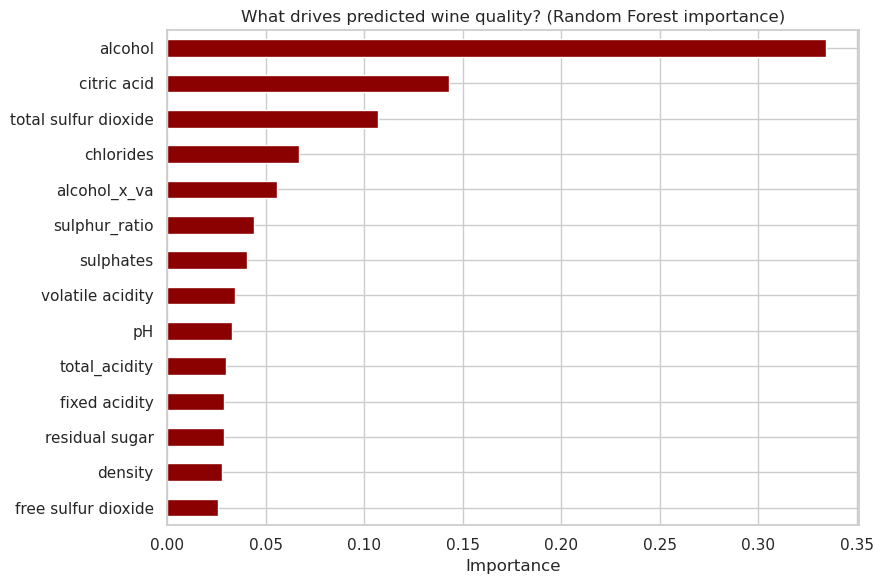

In [17]:
# Step 5a — Feature importance (tuned Random Forest Regressor)
importances = pd.Series(grid.best_estimator_.feature_importances_,
                        index=X.columns).sort_values(ascending=False)
print("Random Forest feature importances (tuned model):")
print(importances.round(4))
plt.figure(figsize=(9, 6))
importances.plot(kind="barh", color="darkred")
plt.title("What drives predicted wine quality? (Random Forest importance)")
plt.xlabel("Importance"); plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

Linear Regression standardised coefficients (negative -> lowers quality):
alcohol_x_va           -0.300
sulphates              -0.080
volatile acidity       -0.078
residual sugar         -0.062
density                -0.022
fixed acidity          -0.007
free sulfur dioxide    -0.003
total_acidity           0.005
chlorides               0.011
pH                      0.018
sulphur_ratio           0.088
total sulfur dioxide    0.100
citric acid             0.152
alcohol                 0.404
dtype: float64


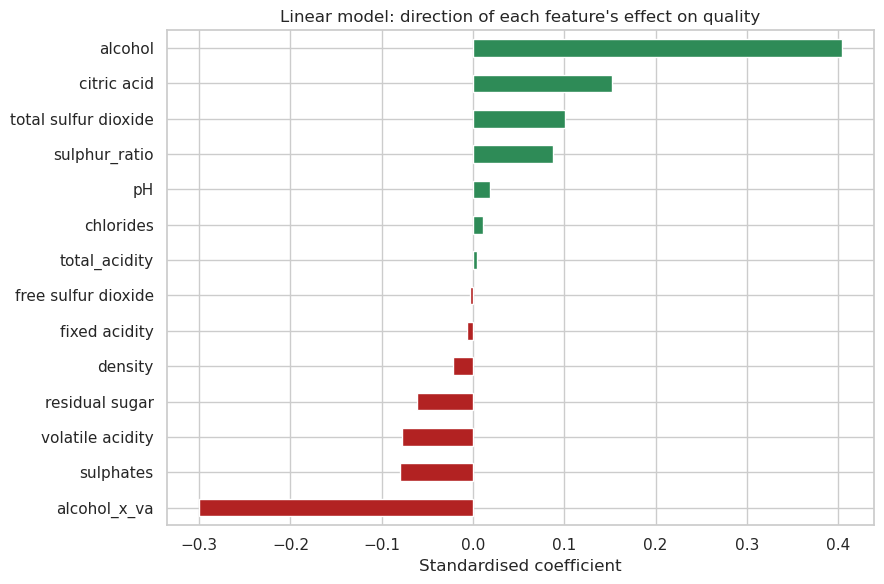

In [18]:
# Step 5b — Linear Regression coefficients (standardised — direction + size)
lr_pipe = reg_models["Linear Regression"]
coefs = pd.Series(lr_pipe.named_steps["m"].coef_, index=X.columns).sort_values()
print("Linear Regression standardised coefficients (negative -> lowers quality):")
print(coefs.round(3))
plt.figure(figsize=(9, 6))
coefs.plot(kind="barh", color=["firebrick" if v < 0 else "seagreen" for v in coefs])
plt.title("Linear model: direction of each feature's effect on quality")
plt.xlabel("Standardised coefficient"); plt.tight_layout(); plt.show()

In [19]:
# Step 5c — Partial-dependence-style insight: mean quality by binned drivers
for col, bins, labels in [
    ("alcohol", [8, 9.5, 10.2, 11, 15], ["8-9.5", "9.5-10.2", "10.2-11", "11+"]),
    ("volatile acidity", [0, 0.4, 0.55, 0.7, 1.6], ["<0.40", "0.40-0.55", "0.55-0.70", ">0.70"]),
    ("sulphates", [0, 0.55, 0.65, 0.8, 2.0], ["<0.55", "0.55-0.65", "0.65-0.80", ">0.80"]),
]:
    binned = pd.cut(df[col], bins=bins, labels=labels)
    summary = df.groupby(binned, observed=True)["quality"].agg(["count", "mean"]).round(3)
    print(f"\nMean quality by {col}:")
    print(summary)
    print(f"  Spread (best bin - worst bin): {summary['mean'].max() - summary['mean'].min():.2f} quality points")
print("\nMean alcohol by quality score:")
print(df.groupby("quality")["alcohol"].mean().round(2))
print("\nMean volatile acidity by quality score:")
print(df.groupby("quality")["volatile acidity"].mean().round(3))


Mean quality by alcohol:
          count   mean
alcohol               
8-9.5       374  5.227
9.5-10.2    344  5.395
10.2-11     283  5.696
11+         358  6.198
  Spread (best bin - worst bin): 0.97 quality points

Mean quality by volatile acidity:
                  count   mean
volatile acidity              
<0.40               387  6.054
0.40-0.55           377  5.655
0.55-0.70           393  5.402
>0.70               202  5.168
  Spread (best bin - worst bin): 0.89 quality points

Mean quality by sulphates:
           count   mean
sulphates              
<0.55        357  5.227
0.55-0.65    465  5.516
0.65-0.80    342  5.962
>0.80        195  6.010
  Spread (best bin - worst bin): 0.78 quality points

Mean alcohol by quality score:
quality
3     9.96
4    10.27
5     9.89
6    10.66
7    11.49
8    12.16
Name: alcohol, dtype: float64

Mean volatile acidity by quality score:
quality
3    0.885
4    0.694
5    0.579
6    0.496
7    0.404
8    0.428
Name: volatile acidity, dtype: fl

Residuals (actual - predicted), tuned RF:
  Mean: -0.012 | Std: 0.638 | Mean |residual|: 0.492
  Share of predictions within +/-1 quality point: 89.3%

Error by true quality score:


,count,mean_residual,MAE
quality,,,
3,2,-1.659,1.659
4,14,-1.320,1.320
5,109,-0.338,0.356
6,110,0.236,0.399
7,33,0.702,0.702
8,4,1.543,1.543


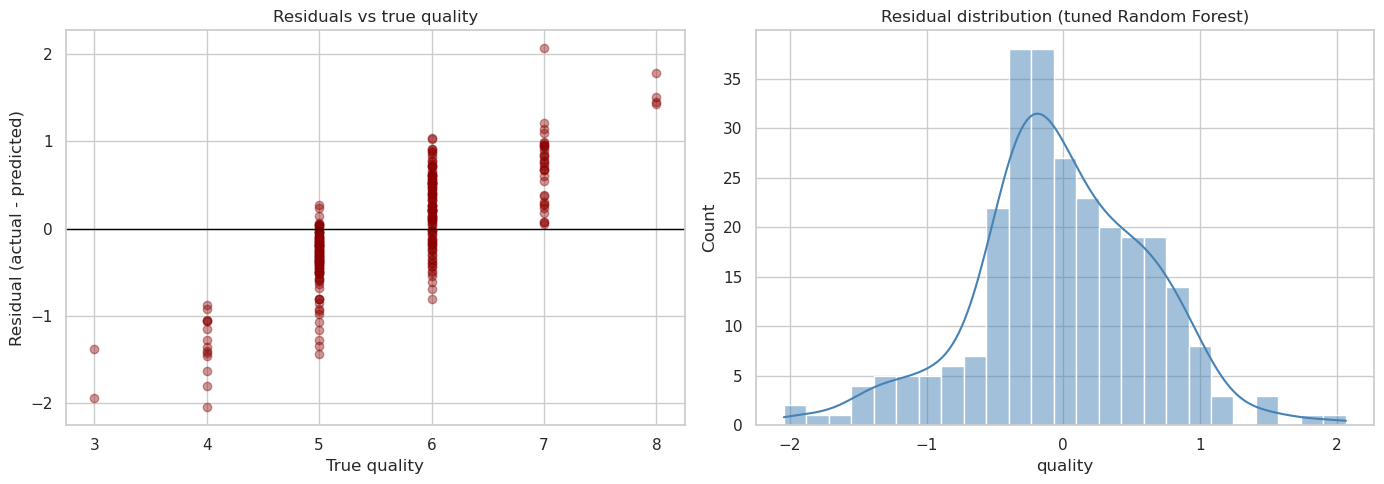

In [20]:
# Step 5d — Residual analysis (tuned Random Forest) + error by quality score
resid = y_test - pred_tuned
print("Residuals (actual - predicted), tuned RF:")
print("  Mean: %.3f | Std: %.3f | Mean |residual|: %.3f"
      % (resid.mean(), resid.std(), np.abs(resid).mean()))
print("  Share of predictions within +/-1 quality point: %.1f%%"
      % (100 * (np.abs(resid) <= 1).mean()))

err_by_score = pd.DataFrame({"quality": y_test.values, "residual": resid,
                             "abs_error": np.abs(resid)}).groupby("quality").agg(
    count=("residual", "size"), mean_residual=("residual", "mean"),
    MAE=("abs_error", "mean")).round(3)
print("\nError by true quality score:")
display(err_by_score)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_test, resid, alpha=0.4, color="darkred")
axes[0].axhline(0, color="black", lw=1)
axes[0].set_xlabel("True quality"); axes[0].set_ylabel("Residual (actual - predicted)")
axes[0].set_title("Residuals vs true quality")
sns.histplot(resid, bins=25, kde=True, ax=axes[1], color="steelblue")
axes[1].set_title("Residual distribution (tuned Random Forest)")
plt.tight_layout(); plt.show()

### Step 5 — What knowledge was actually discovered?

**The headline.** The single strongest driver of perceived quality is **alcohol content** — Pearson r = +0.48 with quality, Random Forest importance 0.33 (a third of all signal), and a standardised linear coefficient of +0.40, by far the largest. Wines in the top alcohol bin (11%+) average roughly a full quality point above wines in the lowest bin (8–9.5%). Next come **citric acid** (r = +0.23, importance 0.14 — freshness/crispness) and **sulphates** (r = +0.25 — associated with aroma and body). On the negative side, **volatile acidity** is the clearest quality killer (r = −0.39, the strongest negative correlation): the vinegar-like fault it signals is exactly what trained tasters penalise. Total sulphur dioxide (r = −0.19) and density (r = −0.17) also drag quality down.

**What was already known vs what is new here.**

| Finding | Status |
|---|---|
| Alcohol ↑ ⇒ quality ↑ | Known in the wine literature (Cortez et al. 2009 report the same); **confirmed** here with a second method and quantified: ~1 quality point across the alcohol range |
| Volatile acidity ↓ ⇒ quality ↑ | Known (volatile acidity = acetic-acid fault); **confirmed**, and it is the strongest *negative* signal in the data |
| Sulphates ↑ ⇒ quality ↑ | Known qualitatively; **confirmed**: Pearson r = +0.25, Random Forest importance 0.04 |
| Residual sugar ≈ irrelevant (r = +0.01) | **Surprising but consistent**: for these dry reds, sweetness does not move the panel score — a useful correction to folk wisdom |
| Engineered features help only slightly | **New for this run**: total acidity, sulphur ratio and the alcohol×volatile-acidity interaction add just +0.009 R² — the raw features already carry the signal |
| The score is only partly predictable | **Key limitation, quantified**: even the best model explains R² ≈ 0.43 of the variance. ~57% is taster subjectivity, unmeasured factors (grape, vintage, tannin structure) and noise |

**Error analysis.** The model is systematically *conservative at the extremes*: it over-predicts the worst wines and under-predicts the best ones (regression to the mean — visible in the residual-vs-true-quality plot). Mean absolute error is smallest in the crowded middle scores (5–6) and largest for the rare 3s and 8s. For the winery this means: trust the model for ranking ordinary batches, do not trust it to spot a once-in-a-decade wine.

**Classification reading.** Premium-wine detection (quality ≥ 7) reaches ROC-AUC ≈ 0.89–0.90 — the model ranks wines well — but precision/recall trade off sharply: Logistic Regression catches 86% of premium wines at 36% precision (many false alarms), while Random Forest is balanced at 55% precision / 49% recall (F1 0.51). For a QC gate, the Random Forest operating point is the honest default; the Logistic model is the right choice only if missing a premium batch is costlier than a false alarm.

---
## Step 6 — Deployment / Knowledge Use

KDD does not end at a metric. The last step is *using* the knowledge — and being explicit about where it stops applying.

**How a winery would use this.**
1. **Pre-release QC screen.** Run every finished batch's lab panel through the tuned Random Forest; flag batches predicted below 5 for a human re-taste before release, and fast-track batches predicted ≥ 7 for premium labelling review.
2. **Blending guidance (directional, not a recipe).** The model says: protect alcohol level, keep volatile acidity low, do not over-dose total SO₂. Use it to *rank* candidate blends by predicted quality and taste-test the top few — never to auto-approve a blend.
3. **Monitoring.** Track prediction drift monthly: if the distribution of incoming lab measurements shifts (new vintage, new supplier), re-validate R² on a fresh labelled sample. Retrain when R² drops materially or when the panel composition changes, because the target *is* human judgement.
4. **Feedback loop.** Log every panel score against the prediction; the growing labelled set is the training data for the next model version.

**Limits — stated plainly.**
- Sensory scores are **subjective**: the same wine can score differently with a different panel. The model's ceiling (~R² 0.43) reflects that, not a modelling failure.
- **Single region, single style:** Vinho Verde reds only. Do not apply to white wine, other regions, or other vintages without re-validation.
- **Correlation ≠ causation.** Alcohol correlates with quality, but much of that is ripeness and grape quality, not alcohol itself. Adding alcohol to a wine will not make it better — do not use this model as a recipe.
- The engineered features added almost nothing; the value is in the *ranking and the drivers*, not in squeezing the last 0.01 of R².

**Reproducibility.** Seed 42 everywhere; all transformers fit on train only; dataset pinned to the UCI URL; `requirements.txt` in the project folder.

In [21]:
# Step 6 — Deployment demo: a predict function a winery QC script would call
import pickle

# Refit the tuned model on ALL cleaned data for deployment (standard practice:
# the test set has served its purpose; the shipped model uses every labelled wine)
final_model = Pipeline([("pre", preprocessor),
                        ("m", RandomForestRegressor(n_estimators=500, max_depth=10,
                                                     min_samples_leaf=5,
                                                     random_state=RANDOM_STATE, n_jobs=-1))])
final_model.fit(X, y_reg)
print("Final model refit on all", len(X), "wines with tuned hyperparameters.")

def predict_quality(wine: dict) -> dict:
    """Predict the sensory quality of one wine from its lab measurements."""
    row = pd.DataFrame([wine])
    row = add_features(row)[X.columns]
    pred = float(final_model.predict(row)[0])
    return {"predicted_quality": round(pred, 2),
            "premium_likely": bool(pred >= 6.5)}

# Example: a plausible good wine vs a plausible faulty wine
good = {"fixed acidity": 8.0, "volatile acidity": 0.35, "citric acid": 0.4,
        "residual sugar": 2.0, "chlorides": 0.05, "free sulfur dioxide": 15,
        "total sulfur dioxide": 35, "density": 0.995, "pH": 3.3,
        "sulphates": 0.8, "alcohol": 12.5}
faulty = {"fixed acidity": 7.0, "volatile acidity": 1.1, "citric acid": 0.05,
          "residual sugar": 2.5, "chlorides": 0.12, "free sulfur dioxide": 8,
          "total sulfur dioxide": 90, "density": 0.999, "pH": 3.6,
          "sulphates": 0.45, "alcohol": 9.0}
print("Good-profile wine :", predict_quality(good))
print("Faulty-profile wine:", predict_quality(faulty))

Final model refit on all 1359 wines with tuned hyperparameters.
Good-profile wine : {'predicted_quality': 6.89, 'premium_likely': True}


Faulty-profile wine: {'predicted_quality': 4.56, 'premium_likely': False}


---
## Conclusion

Following Fayyad et al.'s KDD process end to end — selection, preprocessing, transformation, data mining, interpretation, and deployment — on 1,359 unique red wines:

- **Alcohol is the dominant driver** of perceived quality (r = +0.48, importance 0.33); **volatile acidity is the main destroyer** (r = −0.39).
- The best regression model (tuned Random Forest) reaches **R² ≈ 0.43, RMSE ≈ 0.64** — useful for ranking and QC screening, not for replacing tasters.
- Premium-wine detection (quality ≥ 7) reaches **ROC-AUC ≈ 0.89**, with a precision/recall trade-off the winery must choose explicitly.
- Feature engineering added almost nothing (+0.009 R²) — a genuine negative result, and exactly the kind of thing the KDD interpretation step exists to surface.
- The honest ceiling is human subjectivity: ~57% of the variance in sensory scores is not in the lab measurements. That is the knowledge — and the limit of it.

*Dataset: Cortez, Cerdeira, Almeida & Reis (2009), UCI Machine Learning Repository. Methodology: Fayyad, Piatetsky-Shapiro & Smyth (1996), "From Data Mining to Knowledge Discovery in Databases", AI Magazine 17(3).*